# 02 · Six-week store-day sales forecast: backtest, challenger, intervals, staffing

**Summary.** The production forecast reproduces the published backtest exactly. It is HistGradientBoosting on log sales
with 27 features, from `etl/build_data.py`. RMSPE is 0.1102, MAPE 7.93% and network bias −0.6%, and all 41,396 store-day
forecasts match the report to the euro. A rolling-origin backtest over four six-week windows in 2015 shows the published
window was not a lucky one. The champion beats every baseline in every fold: MAPE 7.7-8.2% against 10.3-12.2% for the
naive rule.

A tuned LightGBM challenger is not better on every fold, and it is worse on the published holdout (RMSPE +0.0012, 95% CI
+0.0003 to +0.0019). By the rule fixed in advance, the published model stays.

Where the error comes from:
* It does not grow over the six weeks.
* It concentrates on days next to public holidays (MAPE 9.0% vs 7.8%).
* 50 stores carry 23% of the squared error, and a recent refurbishment-style closure is 12 times more common among them.
* The model under-forecasts the network by 2-4% in three of four folds.

Two caveats limit what can be used as it stands. RMSPE, the competition metric, is fragile: ten unusual store-days carry 28%
of one fold's squared error. And the P10-P90 bands cover 75% of actual days, not 80%. In staffing terms (an illustrative
EUR 125 of sales per staff-hour), the model cuts mis-planned time from 5.9 to 4.3 hours per store-day. That is about
63,000 staff-hours over six weeks across the network, or 9.5 hours per store per week.

In [1]:
import os, sys, warnings
from pathlib import Path
os.environ.setdefault("OMP_NUM_THREADS", "4")   # share the laptop: other projects run at the same time
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ds" / "dskit").exists())
sys.path.insert(0, str(ROOT / "ds"))
warnings.simplefilter("ignore")              # library warnings print local paths into the outputs
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dskit import set_style, PALETTE, headline, savefig, audit, eda, evaluate, explain, select, report
import features as F
from IPython.display import display
set_style(); pd.set_option("display.float_format", lambda v: f"{v:,.4f}"); pd.set_option("display.width", 160)
FIG, METRICS, SEED = ROOT / "ds" / "figures", ROOT / "ds" / "reports" / "metrics.json", 42

import time
import lightgbm as lgb
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import make_scorer
T_START = time.perf_counter()


def fig_title(fig, title, subtitle=None):
    """Insight title and method subtitle for a multi-panel figure."""
    h = fig.get_figheight()
    fig.suptitle(title, x=0.01, y=1 - 0.04 / h, ha="left", va="top", fontsize=14, fontweight="bold", color=PALETTE["ink"])
    if subtitle:
        fig.text(0.01, 1 - 0.36 / h, subtitle, ha="left", va="top", fontsize=10, color="#5A6478")
    fig.tight_layout(rect=(0, 0, 1, 1 - (0.50 if subtitle else 0.30) / h), pad=0.6)


# Published by etl/build_data.py (data/model_metrics.csv) and quoted in the README and the report
PUBLISHED = {"forecast_rmspe_model": 0.1102, "forecast_rmspe_baseline": 0.148, "forecast_mape_model": 0.0793,
             "forecast_mape_baseline": 0.1099, "forecast_network_bias": -0.006, "forecast_horizon_days": 43}
pub_file = ROOT / "data" / "model_metrics.csv"
if pub_file.exists():                         # data/ is rebuilt locally by the ETL (not committed: licence)
    on_disk = pd.read_csv(pub_file).set_index("Metric")["Value"]
    assert all(abs(PUBLISHED[k] - float(on_disk[k])) < 1e-9 for k in PUBLISHED), "README numbers and data/model_metrics.csv disagree"
    print("published metrics match data/model_metrics.csv")

published metrics match data/model_metrics.csv


## 1. Data and features

`features.py` rebuilds the ETL's 27 features with the same code path and row order: calendar (weekday, day of month,
month, week and day of year), promotion and holiday flags, days to/since public and school holidays, store attributes
(format, assortment, state, competitor distance and age, loyalty promotion), and store-level encodings of log sales
(store mean and volatility; store x weekday, x promo, x month, x weekday x promo means; the last 8 weeks' level vs the
long-run mean). The encodings are the only features learnt from sales, so they are rebuilt **for every forecast origin
from data before it**. `tests/test_features.py` rewrites all future sales and checks that no feature changes.

In [2]:
tr, stores, fact, X0 = F.build_frame(ROOT)
spells = F.closure_spells(tr, min_days=5)          # refurbishment-style closures, for the error analysis
del tr
CATS = {c: pd.CategoricalDtype(sorted(X0[c].unique())) for c in F.CAT_FEATS}
FORMAT = dict(enumerate(sorted(stores["StoreType"].unique())))       # cat codes -> a/b/c/d
gap_stores = set(stores["Store"]) - set(fact.loc[(fact["Date"] >= "2014-07-01") & (fact["Date"] <= "2014-12-31"), "StoreKey"])


def split(cut, end, frame=None):
    """Encodings from rows before `cut`; returns (train rows, test rows in [cut, end))."""
    Xc = F.store_encodings(X0 if frame is None else frame, cut)
    trn, tst = Xc[Xc["Date"] < cut].copy(), Xc[(Xc["Date"] >= cut) & (Xc["Date"] < end)].copy()
    del Xc
    return trn, tst


def lgb_frame(d):
    out = d[F.FEATS].copy()
    for c, t in CATS.items():
        out[c] = out[c].astype(t)
    return out


def fit_champion(trn):
    """The production model, exactly as in etl/build_data.py."""
    m = HistGradientBoostingRegressor(**F.HGB_PARAMS, categorical_features=[F.FEATS.index(c) for c in F.CAT_FEATS])
    return m.fit(trn[F.FEATS], np.log1p(trn["Sales"]))


print(f"{len(X0):,} open store-days, {X0['StoreKey'].nunique():,} stores, {len(F.FEATS)} features")

844,338 open store-days, 1,115 stores, 27 features


## 2. Validation design: rolling origin, six-week windows

The forecast is made on a Friday for the next six weeks, so the backtest does the same thing four times. Each fold trains
on everything before its origin (expanding window), rebuilds the store encodings from that history only, and scores the
next 42 days. The last fold is the ETL's published backtest (19 June - 31 July 2015, 43 days). All test windows are in
2015, after the 180-store gap, so every fold scores the full network. They include Easter, Labour Day, Ascension and
Whitsun, so holiday handling is tested too.

,train up to,test from,test to,days,test store-days,network-wide closures (holidays)
fold,,,,,,
Fold 1,2015-02-12,2015-02-13,2015-03-26,42,40175,none
Fold 2,2015-03-26,2015-03-27,2015-05-07,42,37045,"03 Apr, 06 Apr, 01 May"
Fold 3,2015-05-07,2015-05-08,2015-06-18,42,37472,"14 May, 25 May, 04 Jun"
Holdout (ETL),2015-06-18,2015-06-19,2015-07-31,43,41396,none


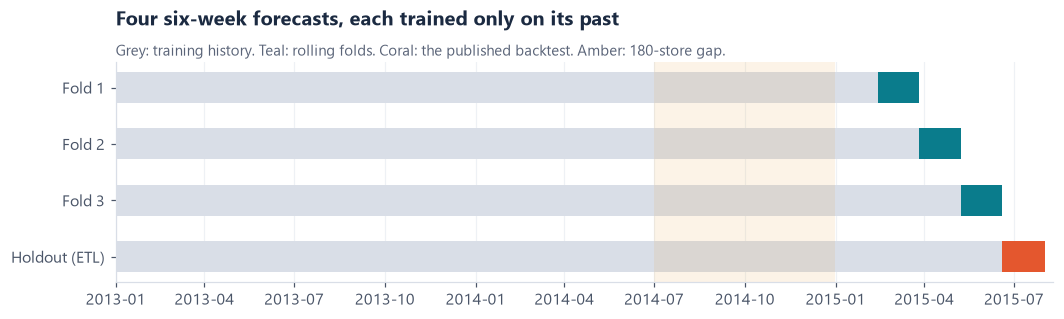

In [3]:
CUTS = ["2015-02-13", "2015-03-27", "2015-05-08", "2015-06-19"]
FOLDS = F.fold_windows(CUTS)
fold_names = ["Fold 1", "Fold 2", "Fold 3", "Holdout (ETL)"]
trading = fact.groupby("Date")["StoreKey"].nunique()
all_days = pd.date_range(X0["Date"].min(), X0["Date"].max(), freq="D")
closed_holidays = [d for d in all_days if d.day_of_week < 6 and trading.get(d, 0) < 0.5 * trading.max()]   # most stores shut
design = pd.DataFrame([{"fold": n, "train up to": (c - pd.Timedelta(days=1)).date(), "test from": c.date(), "test to": (e - pd.Timedelta(days=1)).date(),
                        "days": (e - c).days, "test store-days": int(((X0["Date"] >= c) & (X0["Date"] < e)).sum()),
                        "network-wide closures (holidays)": ", ".join(d.strftime("%d %b") for d in closed_holidays if c <= d < e) or "none"}
                       for n, (c, e) in zip(fold_names, FOLDS)]).set_index("fold")
display(design)
assert FOLDS[-1][0] == F.HOLDOUT_CUT and (FOLDS[-1][1] - FOLDS[-1][0]).days == PUBLISHED["forecast_horizon_days"]

fig, ax = plt.subplots(figsize=(11, 2.6))
for i, (n, (c, e)) in enumerate(zip(fold_names, FOLDS)):
    ax.barh(i, (c - X0["Date"].min()).days, left=X0["Date"].min(), color=PALETTE["light"], height=0.55)
    ax.barh(i, (e - c).days, left=c, color=PALETTE["coral"] if "Holdout" in n else PALETTE["teal"], height=0.55)
ax.axvspan(pd.Timestamp("2014-07-01"), pd.Timestamp("2014-12-31"), color=PALETTE["amber"], alpha=0.12, lw=0)
ax.set_yticks(range(4), fold_names); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(pd.Timestamp("2013-01-01"), pd.Timestamp("2015-08-10"))
headline(ax, "Four six-week forecasts, each trained only on its past", "Grey: training history. Teal: rolling folds. Coral: the published backtest. Amber: 180-store gap.")
plt.show()

## 3. Parity: reproduce the published backtest

Before extending anything, refit the production model (HistGradientBoosting on log sales, 600 iterations, the ETL's
parameters) on the published split and check the headline numbers.

In [4]:
c_h, e_h = FOLDS[-1]
trn_h, tst_h = split(c_h, e_h)
t0 = time.perf_counter()
champ_h = fit_champion(trn_h)
fit_seconds = time.perf_counter() - t0
pred_h = np.expm1(champ_h.predict(tst_h[F.FEATS]))
base_h = F.naive_baseline(trn_h, tst_h, c_h)
parity = pd.DataFrame({
    "published": [PUBLISHED["forecast_rmspe_model"], PUBLISHED["forecast_mape_model"], PUBLISHED["forecast_rmspe_baseline"],
                  PUBLISHED["forecast_mape_baseline"], PUBLISHED["forecast_network_bias"]],
    "reproduced": [F.rmspe(tst_h["Sales"], pred_h), F.mape(tst_h["Sales"], pred_h), F.rmspe(tst_h["Sales"], base_h),
                   F.mape(tst_h["Sales"], base_h), pred_h.sum() / tst_h["Sales"].sum() - 1]},
    index=["RMSPE, model", "MAPE, model", "RMSPE, naive baseline", "MAPE, naive baseline", "Network bias"])
parity["difference"] = parity["reproduced"] - parity["published"]
display(parity)
assert abs(parity.loc["RMSPE, model", "difference"]) < 0.003 and abs(parity.loc["MAPE, model", "difference"]) < 0.002
assert abs(parity.loc["RMSPE, naive baseline", "difference"]) < 0.003 and abs(parity.loc["Network bias", "difference"]) < 0.002
fc_file = ROOT / "data" / "fact_forecast.csv"
if fc_file.exists():
    pub_fc = pd.read_csv(fc_file, parse_dates=["Date"])
    j = tst_h[["StoreKey", "Date"]].assign(mine=np.round(pred_h)).merge(pub_fc, on=["StoreKey", "Date"])
    print(f"row-level check vs the published forecast: {len(j):,} of {len(pub_fc):,} rows matched, max |difference| EUR {(j['mine'] - j['Forecast']).abs().max():.0f}")
print(f"champion fit: {fit_seconds:.0f} s, {champ_h.n_iter_} iterations; error reduction vs naive (MAPE): "
      f"{1 - parity.loc['MAPE, model', 'reproduced'] / parity.loc['MAPE, naive baseline', 'reproduced']:.0%}")

,published,reproduced,difference
"RMSPE, model",0.1102,0.1102,0.0000
"MAPE, model",0.0793,0.0793,-0.0000
"RMSPE, naive baseline",0.1480,0.1480,0.0000
"MAPE, naive baseline",0.1099,0.1099,-0.0000
Network bias,-0.0060,-0.0060,-0.0000


row-level check vs the published forecast: 41,396 of 41,396 rows matched, max |difference| EUR 0
champion fit: 49 s, 600 iterations; error reduction vs naive (MAPE): 28%


The published numbers reproduce exactly, down to the individual store-day forecasts: RMSPE 0.110 against 0.148 for the
naive baseline, MAPE 7.9% against 11.0% (28% less error), and a network bias of −0.6%.

One detail of the ETL baseline matters for honesty. When a store x weekday x promo combination is missing from the
last eight weeks, the ETL falls back to the store's median **over the test window**, so the baseline has seen the
answer for those rows. The cell below counts the rows that touches and scores the honest fallback (training median).
The comparisons in section 6 use the honest version in every fold; the ETL version is kept only for parity.

In [5]:
hist_keys = trn_h[trn_h["Date"] >= c_h - pd.Timedelta(weeks=8)].groupby(["StoreKey", "dow", "Promo"]).size()
uses_fallback = ~tst_h.set_index(["StoreKey", "dow", "Promo"]).index.isin(hist_keys.index)
base_h_honest = F.naive_baseline(trn_h, tst_h, c_h, use_test_fallback=False)
print(f"rows using the fallback: {uses_fallback.sum():,} ({uses_fallback.mean():.2%}); RMSPE with the ETL fallback "
      f"{F.rmspe(tst_h['Sales'], base_h):.4f}, with the honest fallback {F.rmspe(tst_h['Sales'], base_h_honest):.4f}")

rows using the fallback: 0 (0.00%); RMSPE with the ETL fallback 0.1480, with the honest fallback 0.1480


No holdout row needs the fallback (every store x weekday x promo combination appears in the previous eight weeks), so
the published baseline is clean in this window.

## 4. Why not random cross-validation?

A random split puts days from the same week (and the future) into training, so the store encodings and the trees see
the test period's level. On 120 random stores, score the same holdout days two ways: as an honest out-of-time forecast,
and as the test rows of a random 80/20 split of the whole history (same model, same features).

In [6]:
rng = np.random.default_rng(SEED)
sub_ids = rng.choice(stores["Store"].to_numpy(), 120, replace=False)
S = X0[X0["StoreKey"].isin(sub_ids)].reset_index(drop=True)
s_trn, s_tst = split(c_h, e_h, frame=S)
p_oot = np.expm1(fit_champion(s_trn).predict(s_tst[F.FEATS]))
rand_train = rng.random(len(S)) < 0.8
Sr = F.store_encodings(S, F.DATA_END + pd.Timedelta(days=1), train_mask=rand_train)
m_rand = fit_champion(Sr[rand_train])
p_rand = np.expm1(m_rand.predict(Sr.loc[~rand_train, F.FEATS]))
in_window = (Sr.loc[~rand_train, "Date"] >= c_h).to_numpy()
y_rand = Sr.loc[~rand_train, "Sales"].to_numpy()[in_window]
cv_gap = pd.DataFrame({
    "RMSPE": [F.rmspe(s_tst["Sales"], p_oot), F.rmspe(y_rand, p_rand[in_window])],
    "MAPE": [F.mape(s_tst["Sales"], p_oot), F.mape(y_rand, p_rand[in_window])],
}, index=["out-of-time forecast (honest)", "random 80/20 split (test rows in the same window)"])
display(cv_gap.style.format({"RMSPE": "{:.4f}", "MAPE": "{:.2%}"}).set_caption("120 random stores, holdout window 19 Jun - 31 Jul 2015"))
del S, Sr, s_trn, s_tst

,RMSPE,MAPE
out-of-time forecast (honest),0.1002,7.33%
random 80/20 split (test rows in the same window),0.0950,6.23%


On the same stores and the same days, the random split reports MAPE 6.2% against 7.3% out of time. That is about 15%
less error than an honest six-week forecast achieves, because neighbouring days of the same week sit in the training data.
A random split would oversell the model to the operations team. Every comparison below is out of time.

## 5. Candidates and the decision rule

| Model | What it knows | Why it is here |
|---|---|---|
| Seasonal naive | Each store's last week before the origin, same weekday | Textbook floor; ignores promotions |
| Naive (ETL), honest fallback | Median of the last 8 weeks per store x weekday x promo | The published baseline |
| Profile mean | Store x weekday x promo geometric mean over all history | A simple model a planner could run in a spreadsheet |
| **Champion** | HistGradientBoosting on log sales, 27 features (ETL) | Production model; published numbers |
| Challenger | LightGBM on the same features, tuned with Optuna | Is there accuracy left on the table? |

**Decision rule, fixed before looking at the results:** the challenger replaces the champion only if it is better on
every fold **and** a store-level block bootstrap of the pooled RMSPE difference excludes zero. Otherwise the simpler,
published model stays and the challenger is reported as a finding.

### Tuning the challenger without touching any test fold

Optuna (TPE, seeded, a fixed 12 trials so the result does not depend on machine speed) searches leaves, minimum leaf
size, row and column sampling and the L2 penalty. The number of trees and the learning rate are held at 300 and 0.1 to fit
the runtime budget. Tuning uses 150 random stores and two inner validation windows that end before fold 1 starts (May-June 2014 and January-February 2015), each
with its own encodings, so the folds above stay untouched. The objective is RMSPE in euros.

12 trials in 43 s; best inner-fold RMSPE 0.1800
{'subsample_freq': 1, 'random_state': 42, 'verbose': -1, 'n_jobs': 4, 'num_leaves': 56, 'min_child_samples': 36, 'subsample': 0.8057, 'colsample_bytree': 0.7962, 'reg_lambda': 0.0016, 'n_estimators': 300, 'learning_rate': 0.1}


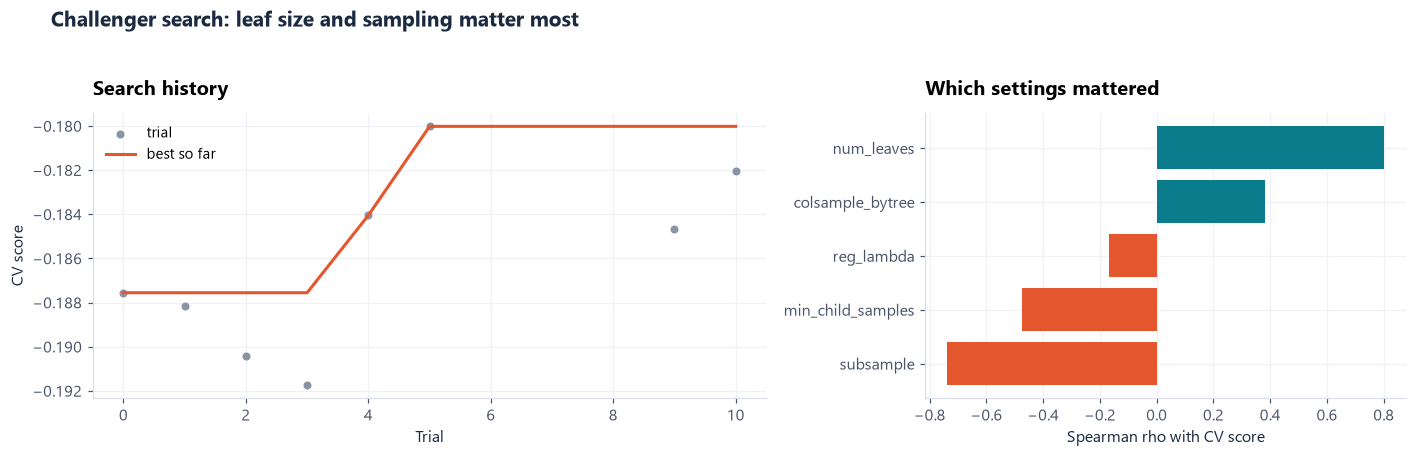

In [7]:
tune_ids = rng.choice(stores["Store"].to_numpy(), 150, replace=False)
T_frame = X0[X0["StoreKey"].isin(tune_ids)].reset_index(drop=True)
parts, splits, off = [], [], 0
for c, e in [("2014-05-09", "2014-06-20"), ("2015-01-02", "2015-02-13")]:
    a, b = split(pd.Timestamp(c), pd.Timestamp(e), frame=T_frame)
    parts += [a, b]
    splits.append((np.arange(off, off + len(a)), np.arange(off + len(a), off + len(a) + len(b))))
    off += len(a) + len(b)
T_stack = pd.concat(parts, ignore_index=True)
neg_rmspe = make_scorer(lambda y, p: -F.rmspe(np.expm1(y), np.expm1(p)))
t0 = time.perf_counter()
best_params, study = select.tune_lgbm(lgb_frame(T_stack), np.log1p(T_stack["Sales"]), select.PredefinedSplits(splits), task="regression",
                                      n_trials=12, timeout=240, scoring=neg_rmspe, seed=SEED, fixed={"n_estimators": 300, "learning_rate": 0.1})
print(f"{len(study.trials)} trials in {time.perf_counter() - t0:.0f} s; best inner-fold RMSPE {-study.best_value:.4f}")
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in best_params.items()})
fig = select.plot_optuna(study, title="Challenger search: leaf size and sampling matter most")
plt.show()
del T_frame, T_stack, parts

## 6. Rolling-origin backtest

In [8]:
MODELS = {"seasonal_naive": "Seasonal naive", "naive_honest": "Naive (ETL rule, honest)", "profile_mean": "Profile mean",
          "champion": "Champion (HGB, ETL)", "challenger": "Challenger (LightGBM, tuned)"}
keep_cols = ["StoreKey", "Date", "Sales", "Customers", "Promo", "StoreType", "state_hol", "SchoolHoliday", "dow", "days_to_hol", "days_since_hol", "comp_months"]
preds, fold_seconds = [], {}
for name, (c, e) in zip(fold_names, FOLDS):
    t0 = time.perf_counter()
    if c == c_h:
        trn, tst, p_champ = trn_h, tst_h, pred_h
    else:
        trn, tst = split(c, e)
        p_champ = np.expm1(fit_champion(trn).predict(tst[F.FEATS]))
    chal = lgb.LGBMRegressor(**best_params).fit(lgb_frame(trn), np.log1p(trn["Sales"]))
    out = tst[keep_cols].assign(fold=name, horizon=(tst["Date"] - c).dt.days + 1, champion=p_champ,
                                challenger=np.expm1(chal.predict(lgb_frame(tst))),
                                naive_etl=F.naive_baseline(trn, tst, c), naive_honest=F.naive_baseline(trn, tst, c, use_test_fallback=False),
                                seasonal_naive=F.seasonal_naive(trn, tst), profile_mean=F.profile_mean(trn, tst))
    preds.append(out)
    if c == c_h:
        chal_h = chal
        # P10 / P90 quantile models for the prediction intervals (section 9), fitted on the same training window
        qparams = dict(n_estimators=150, learning_rate=0.1, num_leaves=31, min_child_samples=100, n_jobs=4, verbose=-1, random_state=SEED)
        q10 = lgb.LGBMRegressor(objective="quantile", alpha=0.10, **qparams).fit(lgb_frame(trn), np.log1p(trn["Sales"]))
        q90 = lgb.LGBMRegressor(objective="quantile", alpha=0.90, **qparams).fit(lgb_frame(trn), np.log1p(trn["Sales"]))
    else:
        del trn, tst
    fold_seconds[name] = time.perf_counter() - t0
    print(f"{name}: {len(out):,} test store-days, {fold_seconds[name]:.0f} s")
del trn_h, trn
P = pd.concat(preds, ignore_index=True)
P["format"] = P["StoreType"].map(FORMAT).str.upper()


def summarise(g):
    return pd.Series({**{f"RMSPE {k}": F.rmspe(g["Sales"], g[k]) for k in MODELS}})


res = P.groupby("fold", sort=False).apply(summarise)
res.columns = [MODELS[c.replace("RMSPE ", "")] for c in res.columns]
res.loc["Mean of folds"] = res.mean()
res.loc["SD of folds"] = res.iloc[:4].std()
display(res.T.style.format("{:.4f}").set_caption("RMSPE per fold (lower is better)"))
mape_tab = P.groupby("fold", sort=False).apply(lambda g: pd.Series({MODELS[k]: F.mape(g["Sales"], g[k]) for k in MODELS}))
bias_tab = P.groupby("fold", sort=False).apply(lambda g: pd.Series({MODELS[k]: g[k].sum() / g["Sales"].sum() - 1 for k in MODELS}))
display(mape_tab.T.style.format("{:.2%}").set_caption("MAPE per fold"))
display(bias_tab.T.style.format("{:+.2%}").set_caption("Network bias per fold (forecast / actual - 1)"))
wape_tab = P.groupby("fold", sort=False).apply(lambda g: pd.Series({MODELS[k]: (g["Sales"] - g[k]).abs().sum() / g["Sales"].sum() for k in MODELS}))
display(wape_tab.T.style.format("{:.2%}").set_caption("WAPE per fold (sum of absolute errors / sum of sales): the staffing-relevant error"))

Fold 1: 40,175 test store-days, 81 s


Fold 2: 37,045 test store-days, 69 s


Fold 3: 37,472 test store-days, 71 s


Holdout (ETL): 41,396 test store-days, 41 s


fold,Fold 1,Fold 2,Fold 3,Holdout (ETL),Mean of folds,SD of folds
Seasonal naive,0.2408,0.2993,0.3140,0.3427,0.2992,0.0429
"Naive (ETL rule, honest)",0.2066,0.1737,0.1473,0.1480,0.1689,0.0280
Profile mean,0.1873,0.1716,0.1539,0.1446,0.1643,0.0189
"Champion (HGB, ETL)",0.1644,0.1045,0.1026,0.1102,0.1204,0.0295
"Challenger (LightGBM, tuned)",0.1559,0.1045,0.1026,0.1114,0.1186,0.0252


fold,Fold 1,Fold 2,Fold 3,Holdout (ETL)
Seasonal naive,16.82%,24.84%,23.11%,23.68%
"Naive (ETL rule, honest)",11.20%,12.20%,10.27%,10.99%
Profile mean,9.62%,12.55%,11.15%,10.71%
"Champion (HGB, ETL)",8.24%,7.95%,7.65%,7.93%
"Challenger (LightGBM, tuned)",8.13%,7.94%,7.54%,8.02%


fold,Fold 1,Fold 2,Fold 3,Holdout (ETL)
Seasonal naive,-10.08%,-22.05%,+6.46%,+8.72%
"Naive (ETL rule, honest)",+0.43%,-7.84%,-4.76%,+2.16%
Profile mean,+0.12%,-8.08%,-6.74%,-2.93%
"Champion (HGB, ETL)",-3.29%,-3.75%,-2.39%,-0.60%
"Challenger (LightGBM, tuned)",-3.48%,-3.36%,-2.25%,-0.68%


fold,Fold 1,Fold 2,Fold 3,Holdout (ETL)
Seasonal naive,17.84%,27.49%,20.82%,21.37%
"Naive (ETL rule, honest)",10.08%,12.91%,10.16%,10.46%
Profile mean,8.78%,13.23%,11.17%,10.70%
"Champion (HGB, ETL)",7.77%,8.12%,7.49%,7.72%
"Challenger (LightGBM, tuned)",7.69%,8.11%,7.39%,7.83%


**How fragile is RMSPE?** It squares percentage errors, so a store-day with unusually low sales (a half-day after a
refurbishment, a local event) can dominate it. Share of each fold's squared percentage error carried by its 10 worst
store-days:

In [9]:
frag = P.groupby("fold", sort=False).apply(lambda g: pd.Series({
    "store-days": len(g),
    "top-10 share of squared % error (champion)": (((g["Sales"] - g["champion"]) / g["Sales"]) ** 2).nlargest(10).sum() / (((g["Sales"] - g["champion"]) / g["Sales"]) ** 2).sum(),
    "median actual sales of those 10 days": g.loc[(((g["Sales"] - g["champion"]) / g["Sales"]) ** 2).nlargest(10).index, "Sales"].median(),
    "median actual sales, all days": g["Sales"].median()}))
display(frag.style.format({"store-days": "{:,.0f}", "top-10 share of squared % error (champion)": "{:.1%}",
                           "median actual sales of those 10 days": "EUR {:,.0f}", "median actual sales, all days": "EUR {:,.0f}"}))

,store-days,top-10 share of squared % error (champion),median actual sales of those 10 days,"median actual sales, all days"
fold,,,,
Fold 1,"40,175",28.0%,"EUR 1,668","EUR 6,226"
Fold 2,"37,045",4.7%,"EUR 3,160","EUR 6,993"
Fold 3,"37,472",8.4%,"EUR 2,314","EUR 6,745"
Holdout (ETL),"41,396",8.8%,"EUR 2,323","EUR 6,414"


**Can the under-forecast be corrected?** The champion under-forecasts the network in every fold. A simple fix a planner
could run: scale each fold's forecast by the previous fold's actual / forecast ratio (known at the new origin, because the
previous fold ends exactly there).

In [10]:
prev_bias = bias_tab[MODELS["champion"]].shift(1)
corr_rows = []
for name in fold_names[1:]:
    g = P[P["fold"] == name]
    adj = g["champion"] / (1 + prev_bias.loc[name])
    corr_rows.append({"fold": name, "factor": 1 / (1 + prev_bias.loc[name]), "bias before": bias_tab.loc[name, MODELS["champion"]],
                      "bias after": adj.sum() / g["Sales"].sum() - 1, "MAPE before": F.mape(g["Sales"], g["champion"]), "MAPE after": F.mape(g["Sales"], adj),
                      "RMSPE before": F.rmspe(g["Sales"], g["champion"]), "RMSPE after": F.rmspe(g["Sales"], adj)})
bias_fix = pd.DataFrame(corr_rows).set_index("fold")
display(bias_fix.style.format({"factor": "{:.3f}", "bias before": "{:+.2%}", "bias after": "{:+.2%}", "MAPE before": "{:.2%}", "MAPE after": "{:.2%}",
                               "RMSPE before": "{:.4f}", "RMSPE after": "{:.4f}"}))

,factor,bias before,bias after,MAPE before,MAPE after,RMSPE before,RMSPE after
fold,,,,,,,
Fold 2,1.034,-3.75%,-0.48%,7.95%,7.78%,0.1045,0.1047
Fold 3,1.039,-2.39%,+1.41%,7.65%,7.90%,0.1026,0.1080
Holdout (ETL),1.025,-0.60%,+1.83%,7.93%,8.36%,0.1102,0.1171


### Champion vs challenger: is the difference real?

Errors are correlated within a store (a store that is having an unusual month is wrong every day), so the interval
resamples **stores**, not store-days: 1,000 store-level block-bootstrap draws of the pooled RMSPE difference.

In [11]:
def store_block_ci(df, a, b, n=1000, seed=SEED):
    s = df.assign(ea=((df["Sales"] - df[a]) / df["Sales"]) ** 2, eb=((df["Sales"] - df[b]) / df["Sales"]) ** 2).groupby("StoreKey")[["ea", "eb"]].agg(["sum", "count"])
    ea, eb, n_a = s[("ea", "sum")].to_numpy(), s[("eb", "sum")].to_numpy(), s[("ea", "count")].to_numpy()
    r = np.random.default_rng(seed)
    d = []
    for _ in range(n):
        ix = r.integers(0, len(s), len(s))
        d.append(np.sqrt(ea[ix].sum() / n_a[ix].sum()) - np.sqrt(eb[ix].sum() / n_a[ix].sum()))
    point = np.sqrt(ea.sum() / n_a.sum()) - np.sqrt(eb.sum() / n_a.sum())
    return point, *np.percentile(d, [2.5, 97.5])


cmp_rows = []
for scope, g in [("Pooled, 4 folds", P), ("Holdout only", P[P["fold"] == "Holdout (ETL)"])]:
    for other in ["challenger", "naive_honest", "profile_mean"]:
        d, lo, hi = store_block_ci(g, "champion", other)
        cmp_rows.append({"scope": scope, "comparison": f"champion - {MODELS[other]}", "RMSPE difference": d, "95% CI low": lo, "95% CI high": hi})
cmp = pd.DataFrame(cmp_rows).set_index(["scope", "comparison"])
display(cmp)
wins_every_fold = bool((res.loc[fold_names, MODELS["challenger"]] < res.loc[fold_names, MODELS["champion"]]).all())
d_pool, lo_pool, hi_pool = cmp.loc[("Pooled, 4 folds", f"champion - {MODELS['challenger']}")]
challenger_wins = wins_every_fold and lo_pool > 0
WINNER = "challenger" if challenger_wins else "champion"
print(f"Challenger better on every fold: {wins_every_fold}; pooled RMSPE gain {d_pool:+.4f} (95% CI {lo_pool:+.4f} to {hi_pool:+.4f}). "
      f"Decision: {'challenger replaces the champion' if challenger_wins else 'keep the champion'}")

RMSPE difference  95% CI low  95% CI high
scope           comparison                                                                        
Pooled, 4 folds champion - Challenger (LightGBM, tuned)            0.0026      0.0014       0.0039
                champion - Naive (ETL rule, honest)               -0.0471     -0.0550      -0.0412
                champion - Profile mean                           -0.0414     -0.0463      -0.0367
Holdout only    champion - Challenger (LightGBM, tuned)           -0.0012     -0.0019      -0.0003
                champion - Naive (ETL rule, honest)               -0.0378     -0.0405      -0.0352
                champion - Profile mean                           -0.0344     -0.0384      -0.0305

Challenger better on every fold: False; pooled RMSPE gain +0.0026 (95% CI +0.0014 to +0.0039). Decision: keep the champion


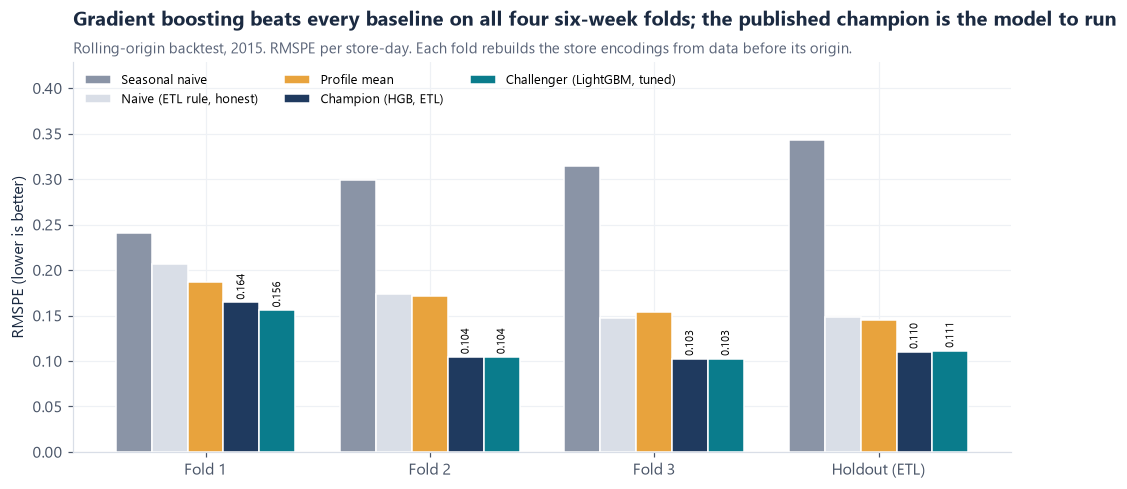

In [12]:
fig, ax = plt.subplots(figsize=(11, 4.6))
order = ["seasonal_naive", "naive_honest", "profile_mean", "champion", "challenger"]
cols = [PALETTE["grey"], PALETTE["light"], PALETTE["amber"], PALETTE["navy"], PALETTE["teal"]]
x = np.arange(len(fold_names))
w = 0.16
for i, (k, c) in enumerate(zip(order, cols)):
    v = res.loc[fold_names, MODELS[k]].to_numpy()
    ax.bar(x + (i - 2) * w, v, width=w, color=c, label=MODELS[k], edgecolor="white")
    if k in ("champion", "challenger"):
        for xx, vv in zip(x + (i - 2) * w, v):
            ax.text(xx, vv + 0.003, f"{vv:.3f}", ha="center", fontsize=7.5, rotation=90, va="bottom")
ax.set_xticks(x, fold_names)
ax.set_ylabel("RMSPE (lower is better)")
ax.legend(ncol=3, fontsize=8.5, loc="upper left")
ax.set_ylim(0, res.loc[fold_names].to_numpy().max() * 1.25)
best_name = "the tuned challenger" if challenger_wins else "the published champion"
headline(ax, f"Gradient boosting beats every baseline on all four six-week folds; {best_name} is the model to run",
         "Rolling-origin backtest, 2015. RMSPE per store-day. Each fold rebuilds the store encodings from data before its origin.")
savefig(fig, "02-backtest", FIG); plt.show()

* **Every fold, every baseline.** The champion's MAPE is 7.7-8.2% across the four folds. The naive rule scores
  10.3-12.2%, the profile mean 9.6-12.6%, and the seasonal naive 17-25% (it ignores promotions, so it fails every other
  week). The ETL holdout is a typical fold, not a lucky one.
* **RMSPE alone would mislead.** Fold 1's RMSPE (0.164) looks far worse than the others (0.103-0.110), but its MAPE
  (8.2%) and WAPE (7.8%) are in line. Ten store-days with unusually low sales carry 28% of fold 1's squared percentage
  error. The competition metric stays for parity; decisions should rest on MAPE and WAPE.
* **Champion vs challenger.** Pooled over four folds the challenger is 0.0026 RMSPE better (95% CI 0.0014-0.0039).
  That gain comes from fold 1 alone, the fold dominated by ten outlier days. The two tie to four decimals on folds 2 and
  3, and on the published holdout the challenger is worse (−0.0012, CI −0.0019 to −0.0003). The rule fixed in advance
  keeps the champion: the published numbers stand and there is no case for a model change.
* **Bias.** The champion under-forecasts the network in every fold (−0.6% to −3.8%), because trees cannot extrapolate
  the 3% growth. Scaling each fold by the previous fold's bias fixes fold 2 but over-corrects fold 3 and the holdout
  (MAPE 7.93% to 8.36%), so it is not a reliable fix.

## 7. Error analysis: where is the forecast wrong, and does it matter?

All four folds pooled (about 165K store-days), for the model to run and the honest naive baseline.

In [13]:
W = WINNER
P["ape"] = (P["Sales"] - P[W]).abs() / P["Sales"]
P["ape_naive"] = (P["Sales"] - P["naive_honest"]).abs() / P["Sales"]
P["near_holiday"] = np.where((P["days_to_hol"] <= 2) | (P["days_since_hol"] <= 2), "Within 2 days of a public holiday", "Normal day")
P["promo_lab"] = np.where(P["Promo"] == 1, "Promotion day", "Regular day")
P["week_ahead"] = "Week " + ((P["horizon"] - 1) // 7 + 1).clip(upper=6).astype(str)


def seg(col):
    g = P.groupby(col).agg(store_days=("Sales", "size"), MAPE=("ape", "mean"), MAPE_naive=("ape_naive", "mean"),
                           bias=(W, "sum"), actual=("Sales", "sum"))
    g["bias"] = g["bias"] / g["actual"] - 1
    return g.drop(columns="actual")


seg_tab = pd.concat({"Store format": seg("format"), "Promotion": seg("promo_lab"), "Holiday proximity": seg("near_holiday"),
                     "Weeks ahead": seg("week_ahead")})
seg_tab.index.names = ["group", "segment"]
display(seg_tab.style.format({"store_days": "{:,.0f}", "MAPE": "{:.2%}", "MAPE_naive": "{:.2%}", "bias": "{:+.2%}"}))

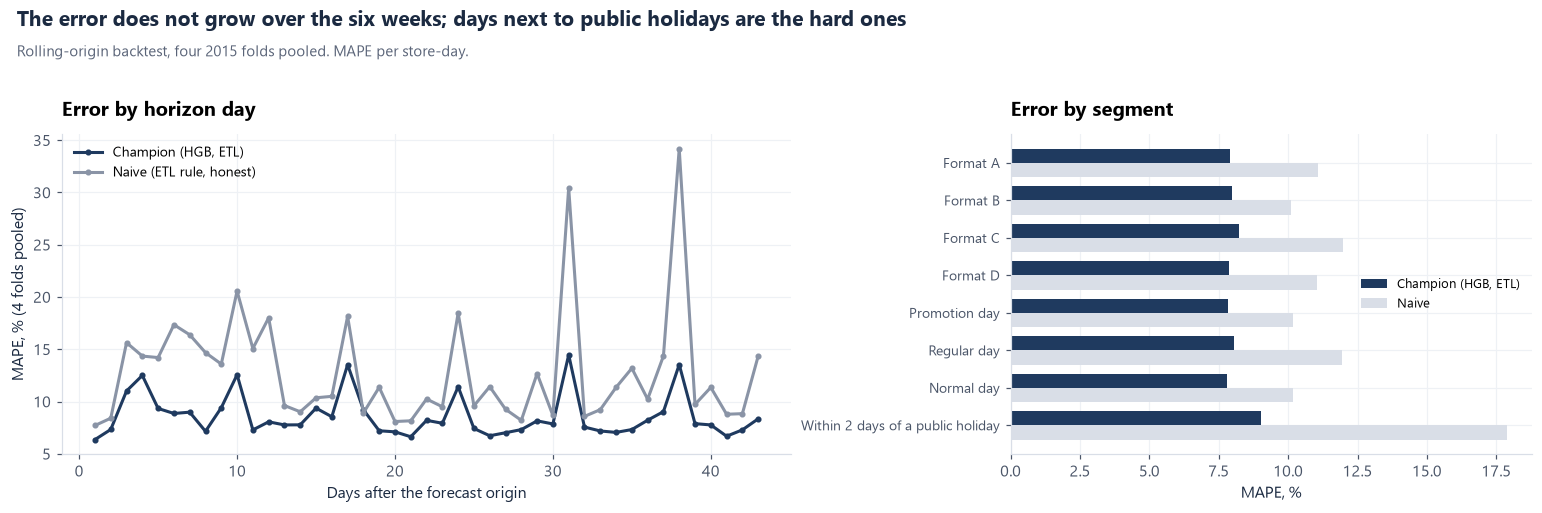

In [14]:
by_h = P.groupby("horizon").agg(model=("ape", "mean"), naive=("ape_naive", "mean"), bias=(W, "sum"), actual=("Sales", "sum"))
by_h["bias"] = by_h["bias"] / by_h["actual"] - 1
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
a1.plot(by_h.index, by_h["model"] * 100, color=PALETTE["navy"], marker="o", ms=3, label=f"{MODELS[W]}")
a1.plot(by_h.index, by_h["naive"] * 100, color=PALETTE["grey"], marker="o", ms=3, label="Naive (ETL rule, honest)")
a1.set(xlabel="Days after the forecast origin", ylabel="MAPE, % (4 folds pooled)", title="Error by horizon day")
a1.legend(fontsize=9)
segs = seg_tab.reset_index()
segs = segs[segs["group"] != "Weeks ahead"]
yy = np.arange(len(segs))
a2.barh(yy, segs["MAPE"] * 100, color=PALETTE["navy"], height=0.38, label=MODELS[W])
a2.barh(yy + 0.38, segs["MAPE_naive"] * 100, color=PALETTE["light"], height=0.38, label="Naive")
a2.set_yticks(yy + 0.19, [f"Format {s}" if g == "Store format" else s for g, s in zip(segs["group"], segs["segment"])], fontsize=9)
a2.invert_yaxis()
a2.set(xlabel="MAPE, %", title="Error by segment")
a2.legend(fontsize=8.5, loc="center right")
fig_title(fig, "The error does not grow over the six weeks; days next to public holidays are the hard ones",
          "Rolling-origin backtest, four 2015 folds pooled. MAPE per store-day.")
savefig(fig, "02-errors", FIG); plt.show()

* **No decay over the horizon.** MAPE is 8.9% in week 1 and 7.4-8.0% in weeks 2-6. The model has no lag features, so
  day 40 is as easy as day 4. The spikes in the horizon chart are dates next to public holidays in one of the folds
  (Easter, 1 May, Ascension, Whit Monday).
* **Holidays are the hard days.** Within two days of a public holiday MAPE rises to 9.0% (7.8% otherwise) and the
  model under-forecasts by 5.2%: it underestimates the stock-up before a closure. The naive rule does far worse there (17.9%).
* **Formats and promotions are handled evenly**: MAPE 7.9-8.2% across formats; 7.8% on promotion days, 8.0% otherwise.

### The worst stores

In [15]:
st_err = P.groupby("StoreKey").agg(days=("Sales", "size"), MAPE=("ape", "mean"), bias=(W, "sum"), actual=("Sales", "sum"))
st_err["bias"] = st_err["bias"] / st_err["actual"] - 1
test_start, test_end = FOLDS[0][0], FOLDS[-1][1]
refurb = spells[(spells["end"] >= test_start - pd.Timedelta(days=60)) & (spells["start"] <= test_end)].groupby("Store").size()
st_err["closure_near_test"] = st_err.index.isin(refurb.index)
st_err["missing_h2_2014"] = st_err.index.isin(gap_stores)
st_err["competitor_opened_2014_15"] = st_err.index.isin(stores.loc[stores["CompOpen"] >= "2014-01-01", "Store"])
st_err["format"] = st_err.index.map(stores.set_index("Store")["StoreType"].str.upper())
worst = st_err.sort_values("MAPE", ascending=False)
display(worst.head(12).drop(columns="actual").style.format({"MAPE": "{:.1%}", "bias": "{:+.1%}"}))
top = worst.head(50)
flags = pd.DataFrame({"worst 50 stores": top[["closure_near_test", "missing_h2_2014", "competitor_opened_2014_15"]].mean(),
                      "all stores": st_err[["closure_near_test", "missing_h2_2014", "competitor_opened_2014_15"]].mean()})
display(flags.style.format("{:.0%}"))
share_top = (P[P["StoreKey"].isin(top.index)]["ape"] ** 2).sum() / (P["ape"] ** 2).sum()
print(f"The worst 50 stores (4.5% of the network) carry {share_top:.0%} of the squared percentage error.")

,days,MAPE,bias,closure_near_test,missing_h2_2014,competitor_opened_2014_15,format
StoreKey,,,,,,,
644,117,24.0%,+0.5%,True,True,False,C
183,128,18.7%,-12.5%,True,True,False,A
1039,139,17.6%,+3.5%,False,False,False,A
576,140,17.4%,-4.1%,False,False,False,C
1081,169,16.9%,-3.2%,False,False,False,B
770,139,16.8%,+8.2%,False,False,True,A
39,139,16.7%,-7.3%,False,False,False,A
192,139,16.3%,-16.4%,False,True,False,D
415,140,16.3%,-3.3%,False,False,False,D


,worst 50 stores,all stores
closure_near_test,12%,1%
missing_h2_2014,14%,16%
competitor_opened_2014_15,18%,10%


The worst 50 stores (4.5% of the network) carry 23% of the squared percentage error.


The 50 worst stores (by MAPE over all four folds) carry 23% of the squared error. A closure of five or more weekdays
around the test period (typically a refurbishment) is 12 times more common among them than in the network (12% vs 1%).
A competitor opening in 2014-15 is almost twice as common (18% vs 10%). Being one of the 180 gap stores is not
over-represented (14% vs 16%), so the gap itself does not hurt the forecast. The business knows about refurbishments and
new competitors in advance. Feeding them into the forecast, or flagging these stores for manual review, is the cheapest
accuracy gain available.

## 8. Residual diagnostics

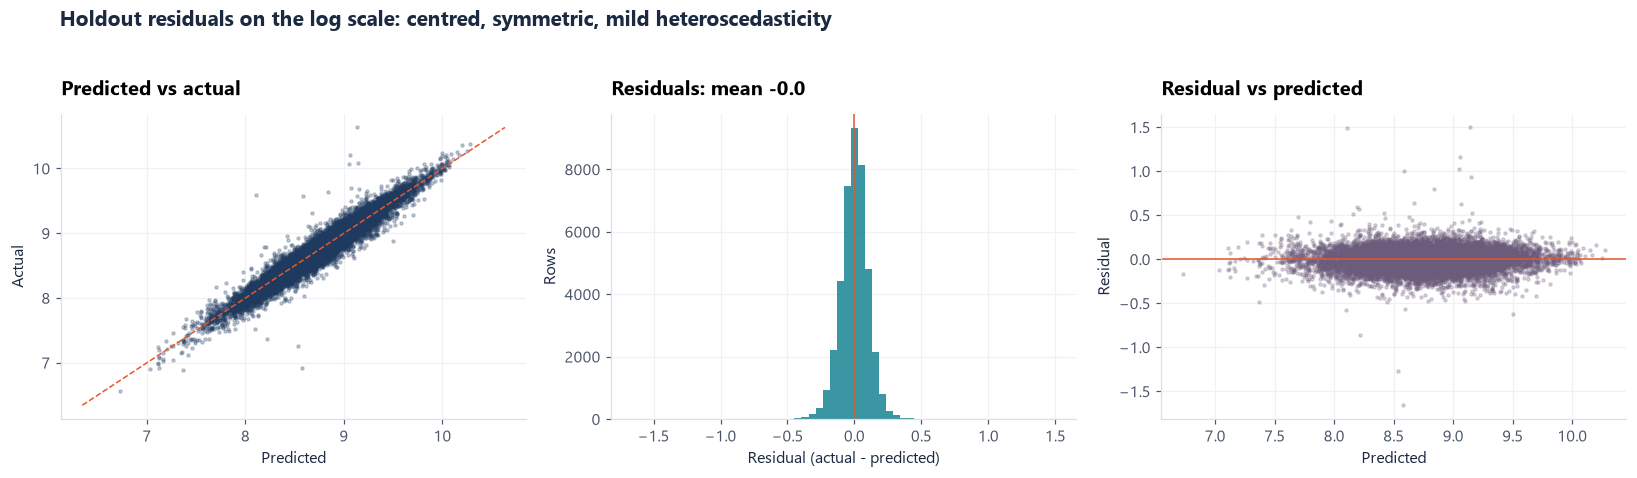

Share of squared log error that is a constant store-level offset within a fold: 18%
Residual skew -0.98; share of store-days with |error| > 25%: 2.16%


In [16]:
H = P[P["fold"] == "Holdout (ETL)"].copy()
fig = evaluate.plot_residuals(np.log(H["Sales"]), np.log(H[W]), title="Holdout residuals on the log scale: centred, symmetric, mild heteroscedasticity")
plt.show()
r = np.log(P["Sales"]) - np.log(P[W])
store_bias = r.groupby([P["fold"], P["StoreKey"]]).transform("mean")
share_level = (store_bias ** 2).sum() / (r ** 2).sum()
print(f"Share of squared log error that is a constant store-level offset within a fold: {share_level:.0%}")
print(f"Residual skew {r.skew():.2f}; share of store-days with |error| > 25%: {(P['ape'] > 0.25).mean():.2%}")

Residuals on the log scale are centred and roughly symmetric, with a longer lower tail (skew −0.98: the occasional very
bad day, such as a partial closure). 18% of the squared error is a constant offset per store within a fold: a store
whose level has shifted stays wrong for six weeks. Re-forecasting weekly with the latest actuals, which `recent_shift`
would then pick up, would remove part of that at no modelling cost.

## 9. Prediction intervals: how sure is each store-day forecast?

Staffing needs a range, not a point. Two ways to get a P10-P90 band, both checked on the untouched holdout:

1. **Quantile models**: LightGBM fitted with the pinball loss at the 10th and 90th percentiles (same features, same
   training window).
2. **Empirical residual quantiles**: the model's own log errors on folds 1-3 (out of time), by week ahead, added to the
   point forecast. Simple, and calibrated on honest errors by construction.

A good 80% interval contains about 80% of actuals and is as narrow as possible.

In [17]:
Xh = lgb_frame(tst_h)
H["q10"], H["q90"] = np.expm1(q10.predict(Xh)), np.expm1(q90.predict(Xh))
H["q10"], H["q90"] = np.minimum(H["q10"], H[W]), np.maximum(H["q90"], H[W])      # quantile models can cross the point forecast
past = P[P["fold"] != "Holdout (ETL)"].assign(lr=lambda d: np.log(d["Sales"]) - np.log(d[W]))
rq = past.groupby("week_ahead")["lr"].quantile([0.1, 0.9]).unstack()
H["e10"] = H[W] * np.exp(H["week_ahead"].map(rq[0.1]))
H["e90"] = H[W] * np.exp(H["week_ahead"].map(rq[0.9]))


def cover(g, lo, hi):
    return pd.Series({"coverage": ((g["Sales"] >= g[lo]) & (g["Sales"] <= g[hi])).mean(), "below P10": (g["Sales"] < g[lo]).mean(),
                      "above P90": (g["Sales"] > g[hi]).mean(), "median width, % of forecast": ((g[hi] - g[lo]) / g[W]).median()})


cov = pd.DataFrame({"Quantile models (LightGBM)": cover(H, "q10", "q90"), "Residual quantiles (folds 1-3)": cover(H, "e10", "e90")}).T
display(cov.style.format("{:.1%}"))
cov_seg = pd.concat({lab: H.groupby(col).apply(lambda g: pd.Series({"quantile models": cover(g, "q10", "q90")["coverage"],
                                                                    "residual quantiles": cover(g, "e10", "e90")["coverage"]}))
                     for lab, col in [("Weeks ahead", "week_ahead"), ("Promotion", "promo_lab"), ("Format", "format")]})
display(cov_seg.style.format("{:.1%}"))

,coverage,below P10,above P90,"median width, % of forecast"
Quantile models (LightGBM),74.6%,12.2%,13.1%,22.3%
Residual quantiles (folds 1-3),76.2%,17.7%,6.1%,24.0%


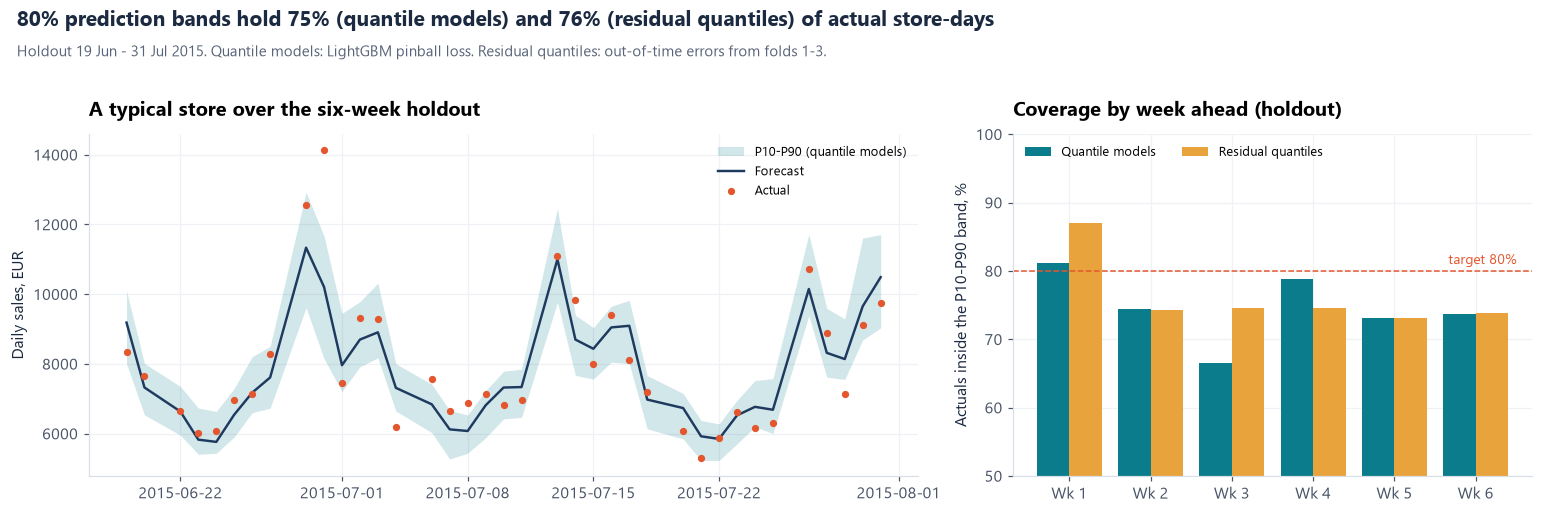

In [18]:
example = H.groupby("StoreKey")["ape"].mean().sort_values().index[len(H["StoreKey"].unique()) // 2]   # a typical (median-error) store
ex = H[H["StoreKey"] == example].sort_values("Date")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
a1.fill_between(ex["Date"], ex["q10"], ex["q90"], color=PALETTE["teal"], alpha=0.18, lw=0, label="P10-P90 (quantile models)")
a1.plot(ex["Date"], ex[W], color=PALETTE["navy"], lw=1.6, label="Forecast")
a1.scatter(ex["Date"], ex["Sales"], s=14, color=PALETTE["coral"], zorder=3, label="Actual")
a1.set(ylabel="Daily sales, EUR", title="A typical store over the six-week holdout")
a1.legend(fontsize=8.5, loc="upper right")
cw = H.groupby("week_ahead").apply(lambda g: pd.Series({"Quantile models": cover(g, "q10", "q90")["coverage"],
                                                        "Residual quantiles": cover(g, "e10", "e90")["coverage"]}))
xw = np.arange(len(cw))
a2.bar(xw - 0.2, cw["Quantile models"] * 100, width=0.4, color=PALETTE["teal"], label="Quantile models")
a2.bar(xw + 0.2, cw["Residual quantiles"] * 100, width=0.4, color=PALETTE["amber"], label="Residual quantiles")
a2.axhline(80, color=PALETTE["coral"], ls="--", lw=1)
a2.text(len(cw) - 0.5, 81, "target 80%", ha="right", fontsize=9, color=PALETTE["coral"])
a2.set_xticks(xw, cw.index.str.replace("Week ", "Wk "))
a2.set(ylim=(50, 100), ylabel="Actuals inside the P10-P90 band, %", title="Coverage by week ahead (holdout)")
a2.legend(fontsize=8.5, loc="upper left", ncol=2)
fig_title(fig, f"80% prediction bands hold {cov.iloc[0]['coverage']:.0%} (quantile models) and {cov.iloc[1]['coverage']:.0%} (residual quantiles) of actual store-days", "Holdout 19 Jun - 31 Jul 2015. Quantile models: LightGBM pinball loss. Residual quantiles: out-of-time errors from folds 1-3.")
savefig(fig, "02-intervals", FIG); plt.show()

Neither method reaches the 80% target on the holdout.
* **Quantile models: 74.6%.** The misses are symmetric (12.2% of actuals below P10, 13.1% above P90): the band is
  simply too narrow.
* **Residual quantiles: 76.2%, but lopsided** (17.7% below, 6.1% above). Folds 1-3 under-forecast more than the
  holdout did, so their residuals push the band too high.

Coverage is similar across promotions and formats; the median band is 22% of the forecast wide (about ±11%). Before
rosters use these bands they need a widening step, conformalised quantile regression calibrated on the most recent fold,
followed by a re-check. As they stand, they are 75% bands, not 80%.

## 10. What drives the forecast (SHAP), cross-checked with permutation importance

,mean_abs_shap,share
feature,,
Store x weekday x promo mean,0.2989,36.8%
Public holiday,0.0654,8.1%
Store x month mean,0.0634,7.8%
Store mean (log),0.0475,5.8%
Week of year,0.0461,5.7%
Year,0.0385,4.7%
Assortment,0.0344,4.2%
Day of year,0.0314,3.9%
Promotion day,0.0240,3.0%


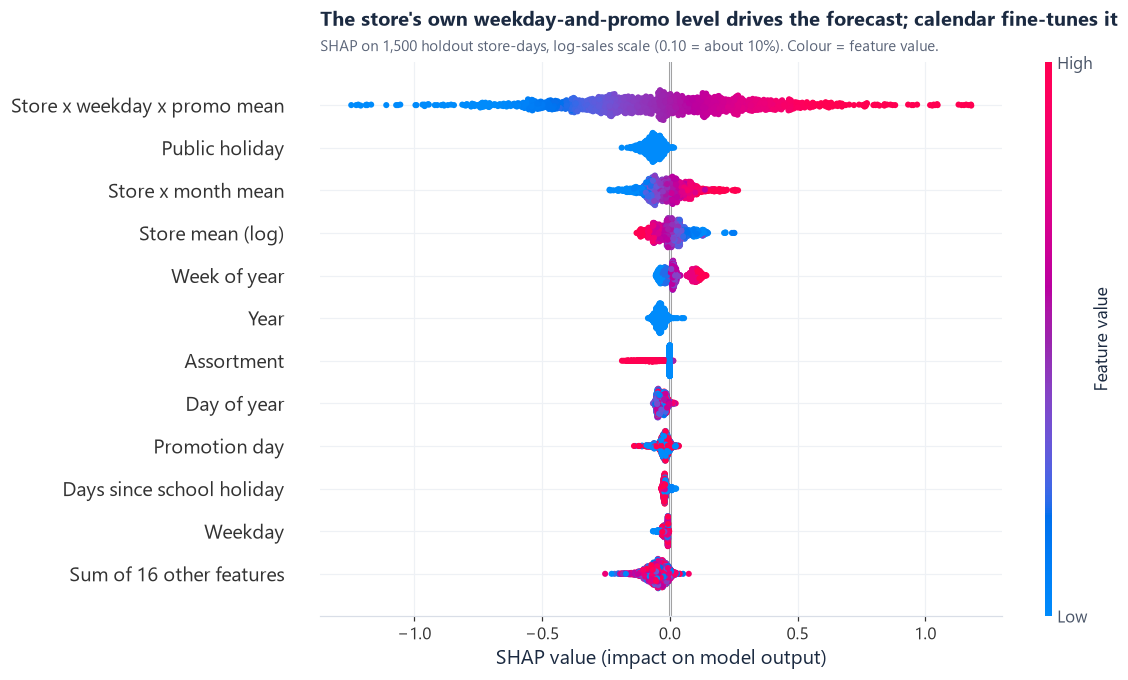

In [19]:
model_w = champ_h if W == "champion" else chal_h
X_explain = tst_h[F.FEATS] if W == "champion" else lgb_frame(tst_h)
e = explain.shap_explanation(model_w, X_explain, sample=1500, seed=SEED)
e.feature_names = [F.FEATURE_LABELS[f] for f in F.FEATS]
imp = explain.shap_importance(e)
display(imp.head(10).style.format({"mean_abs_shap": "{:.4f}", "share": "{:.1%}"}))
fig = explain.plot_shap_beeswarm(e, max_display=12, title="The store's own weekday-and-promo level drives the forecast; calendar fine-tunes it",
                                 subtitle="SHAP on 1,500 holdout store-days, log-sales scale (0.10 = about 10%). Colour = feature value.")
savefig(fig, "02-shap", FIG); plt.show()

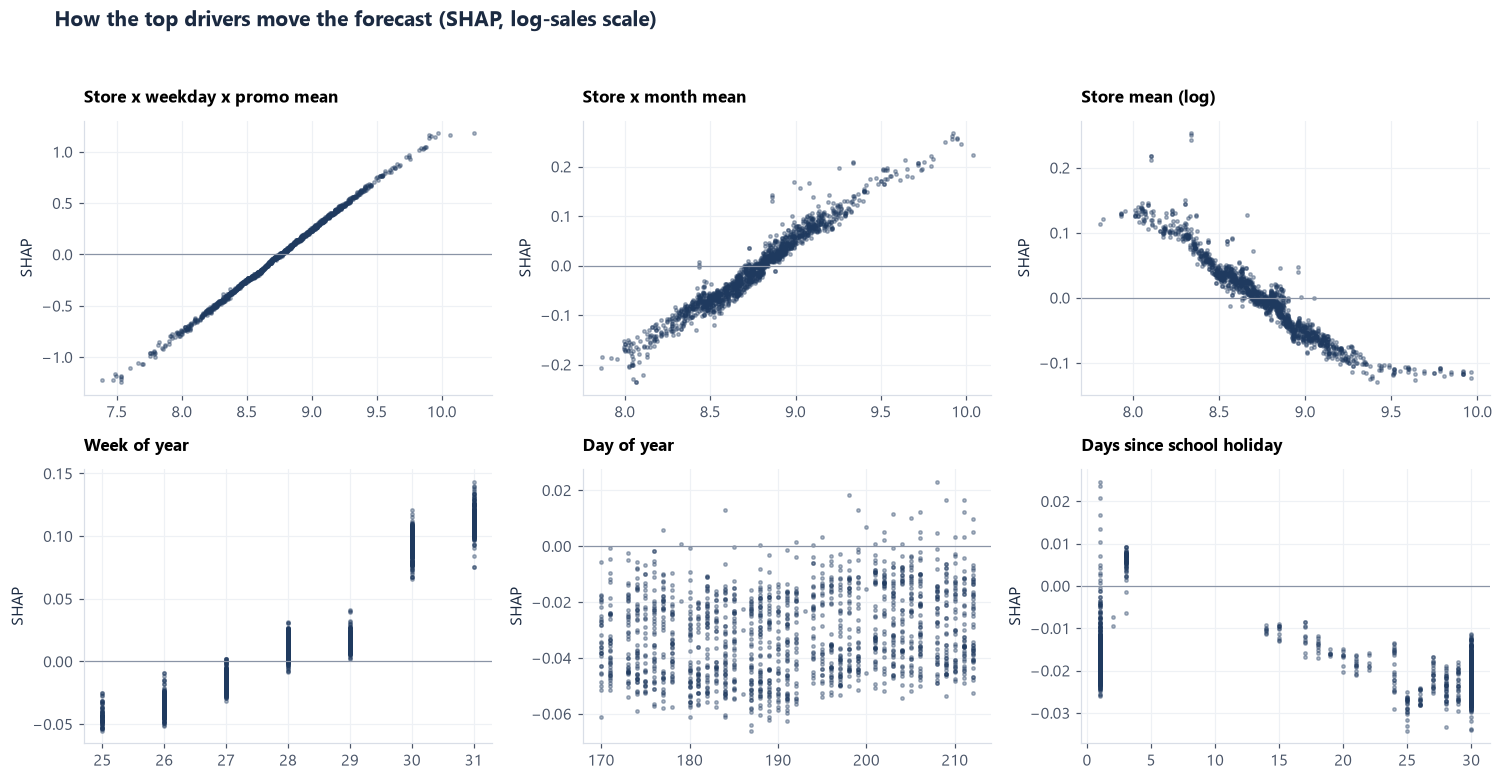

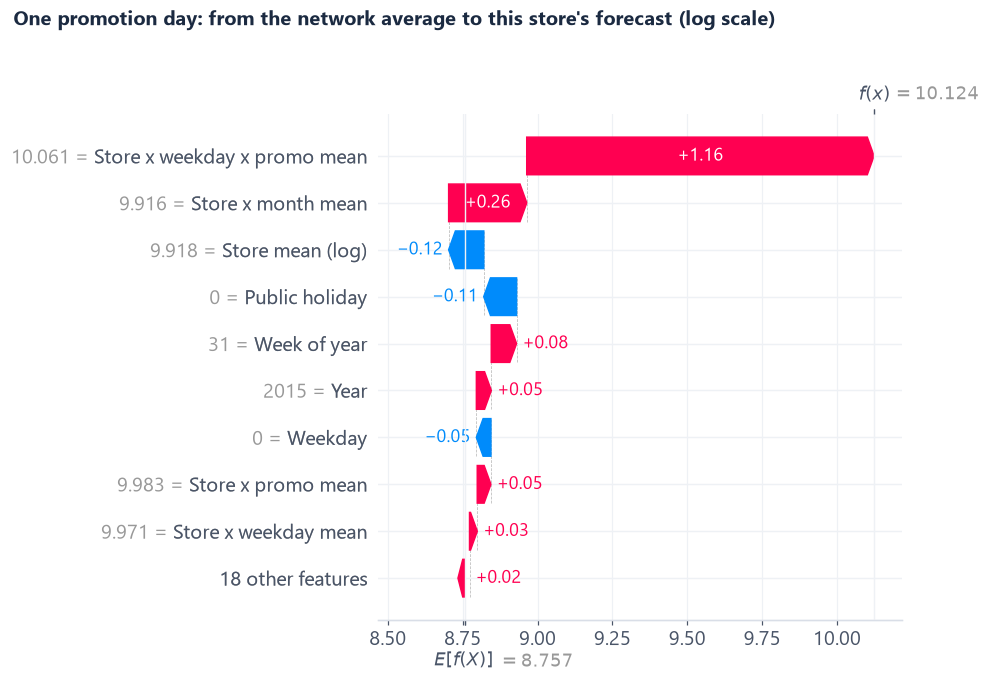

,label,RMSPE increase when shuffled,SHAP rank
feature,,,
store_dow_promo_mean,Store x weekday x promo mean,0.5663,1
store_month_mean,Store x month mean,0.1636,3
store_mean,Store mean (log),0.0973,4
recent_shift,Recent level shift (8 wk),0.0317,16
dom,Day of month,0.0233,12
dow,Weekday,0.0062,11
days_since_school,Days since school holiday,0.0058,10
days_to_school,Days to school holiday,0.0032,21
State,State,0.0026,15


In [20]:
top_feats = [f for f in imp.index if len(np.unique(e.data[:, list(e.feature_names).index(f)])) > 5][:6]   # skip features constant in the window
fig = explain.plot_shap_dependence(e, top_feats, ncols=3, title="How the top drivers move the forecast (SHAP, log-sales scale)")
plt.show()
i_ex = int(np.argmax(np.abs(e.values).sum(1) * (X_explain.sample(1500, random_state=SEED)["Promo"].to_numpy() == 1)))
fig = explain.plot_shap_waterfall(e, i_ex, "One promotion day: from the network average to this store's forecast (log scale)")
plt.show()
perm_idx = tst_h.sample(8000, random_state=SEED).index
perm = explain.permutation_table(model_w, X_explain.loc[perm_idx], np.log1p(tst_h.loc[perm_idx, "Sales"]), scoring=neg_rmspe, n_repeats=3, seed=SEED,
                                 labels=F.FEATURE_LABELS)
cross = perm[["label", "drop_mean"]].rename(columns={"drop_mean": "RMSPE increase when shuffled"}).head(10)
cross["SHAP rank"] = cross["label"].map({f: i + 1 for i, f in enumerate(imp.index)})
display(cross.style.format({"RMSPE increase when shuffled": "{:.4f}"}))

* The store's own weekday x promo level does most of the work: 37% of mean |SHAP| and by far the largest loss when
  shuffled. The forecast is essentially "this store's normal day of this kind", adjusted for month, calendar and holidays.
* SHAP and permutation importance agree on the top encodings but differ on two features, and the difference is
  instructive:
  * **Recent level shift** ranks 16th by SHAP but 4th by permutation. It is small for most stores but decisive for the
    few whose level has moved, and RMSPE punishes exactly those.
  * **Public holiday** ranks 2nd by SHAP but is outside the permutation top 10. Almost no holdout day is a holiday, so
    its SHAP value is mostly a constant offset against a training average that includes holidays; shuffling it barely
    changes accuracy here.

  SHAP shows how the model builds a prediction; permutation shows what matters for accuracy in this window.

## 11. What the forecast is worth in staff hours

The data have no staffing records, so this section states its assumptions and shows how the answer moves with them.

* **Labour standard**: one staff-hour per EUR 125 of sales (illustrative; replace with the chain's own standard).
  Planned hours = forecast / 125. Every euro of error is mis-planned time: too few people (queues, lost sales) or
  too many (wage cost).
* **Scope**: the six-week holdout, 1,115 stores, every open day.

In [21]:
def staffing(df, col, rate):
    err_h = (df["Sales"] - df[col]).abs() / rate
    return pd.Series({"mis-planned hours per store-day": err_h.mean(), "mis-planned hours, network, 6 weeks": err_h.sum(),
                      "share of planned hours": err_h.sum() / (df["Sales"].sum() / rate)})


RATE = 125
stf = pd.DataFrame({MODELS[k]: staffing(H, k, RATE) for k in ["naive_honest", "profile_mean", "champion", "challenger"]}).T
display(stf.style.format({"mis-planned hours per store-day": "{:.2f}", "mis-planned hours, network, 6 weeks": "{:,.0f}", "share of planned hours": "{:.1%}"}))
saved = stf.loc[MODELS["naive_honest"], "mis-planned hours, network, 6 weeks"] - stf.loc[MODELS[W], "mis-planned hours, network, 6 weeks"]
sens = pd.Series({r: (staffing(H, "naive_honest", r)["mis-planned hours, network, 6 weeks"] - staffing(H, W, r)["mis-planned hours, network, 6 weeks"])
                  for r in (100, 125, 150)}, name="hours saved vs naive, 6 weeks")
sens.index = [f"EUR {r} per staff-hour" for r in sens.index]
display(sens.to_frame().style.format("{:,.0f}"))
per_store_week = saved / 1115 / 6
print(f"At EUR {RATE}/hour the model removes {saved:,.0f} mis-planned staff-hours over six weeks vs the naive rule: "
      f"about {per_store_week:.1f} hours per store per week.")

,mis-planned hours per store-day,"mis-planned hours, network, 6 weeks",share of planned hours
"Naive (ETL rule, honest)",5.85,"242,241",10.5%
Profile mean,5.99,"247,862",10.7%
"Champion (HGB, ETL)",4.32,"178,776",7.7%
"Challenger (LightGBM, tuned)",4.38,"181,379",7.8%


,"hours saved vs naive, 6 weeks"
EUR 100 per staff-hour,"79,331"
EUR 125 per staff-hour,"63,465"
EUR 150 per staff-hour,"52,888"


At EUR 125/hour the model removes 63,465 mis-planned staff-hours over six weeks vs the naive rule: about 9.5 hours per store per week.


At the illustrative labour standard, the naive rule mis-plans 5.9 staff-hours per store-day (10.5% of planned hours) and
the champion 4.3 (7.7%). That is about 63,000 fewer mis-planned hours across the network over six weeks, or 9.5 hours
per store per week; at EUR 150 to EUR 100 per staff-hour the saving is 53,000-79,000 hours.

Two caveats. Not every mis-planned hour is a cost, because some slack is absorbed on the shop floor. And the cost is
asymmetric: under-staffing loses sales and service, over-staffing costs wages. With an explicit cost ratio, the right
roster target is a quantile, not the mean. If an under-staffed hour costs twice an over-staffed one, roster to the 67th
percentile, which the quantile models can supply once their calibration is fixed.

In [22]:
elapsed = time.perf_counter() - T_START
hold = res.loc["Holdout (ETL)"]
report.update_metrics(str(METRICS), "02_forecast", {
    "holdout_rmspe_champion": float(hold[MODELS["champion"]]), "holdout_rmspe_challenger": float(hold[MODELS["challenger"]]),
    "holdout_rmspe_naive_etl": float(F.rmspe(H["Sales"], H["naive_etl"])), "holdout_rmspe_naive_honest": float(hold[MODELS["naive_honest"]]),
    "holdout_mape_champion": float(F.mape(H["Sales"], H["champion"])), "holdout_bias_champion": float(H["champion"].sum() / H["Sales"].sum() - 1),
    "folds_rmspe_champion": res.loc[fold_names, MODELS["champion"]].round(4).tolist(),
    "folds_rmspe_challenger": res.loc[fold_names, MODELS["challenger"]].round(4).tolist(),
    "folds_rmspe_naive_honest": res.loc[fold_names, MODELS["naive_honest"]].round(4).tolist(),
    "folds_rmspe_profile_mean": res.loc[fold_names, MODELS["profile_mean"]].round(4).tolist(),
    "folds_rmspe_seasonal_naive": res.loc[fold_names, MODELS["seasonal_naive"]].round(4).tolist(),
    "pooled_rmspe_gain_challenger": {"diff": d_pool, "ci_low": lo_pool, "ci_high": hi_pool}, "winner": W,
    "random_split_rmspe_same_days": float(cv_gap.iloc[1, 0]), "out_of_time_rmspe_same_stores": float(cv_gap.iloc[0, 0]),
    "interval_coverage_quantile": float(cov.iloc[0]["coverage"]), "interval_coverage_residual": float(cov.iloc[1]["coverage"]),
    "interval_width_quantile": float(cov.iloc[0]["median width, % of forecast"]), "interval_width_residual": float(cov.iloc[1]["median width, % of forecast"]),
    "staff_hours_saved_6wk_at_125": float(saved), "wape_champion_folds": wape_tab[MODELS["champion"]].round(4).tolist(),
    "bias_champion_folds": bias_tab[MODELS["champion"]].round(4).tolist(), "rmspe_top10_share_folds": frag.iloc[:, 1].round(3).tolist(), "top_shap_features": list(imp.index[:5]), "challenger_params": best_params,
    "runtime_seconds": elapsed,
})
print(f"metrics saved; notebook runtime {elapsed / 60:.1f} min")

metrics saved; notebook runtime 6.7 min


## 12. Limitations and what I would do next

**Limitations**
* All four backtest windows are in February-July 2015. No fold covers December, the hardest month, because H2 2014
  lacks 180 stores.
* RMSPE is fragile to a handful of low-sales days. The published metric is kept for parity; MAPE and WAPE are the
  decision metrics.
* The model under-forecasts the network by 2-4% in most folds (it has no trend term), so stock planning should not use
  it unadjusted.
* The 80% prediction bands cover 75%.
* The staffing value rests on an assumed labour standard; the source has no rostering data.
* Refurbishments and new competitors are known to the business but not to the model.

**What I would do next**
* Add planned closures and reopenings and competitor openings as features. The worst-store analysis says this is the
  largest single gain.
* Add a trend-aware level (for example a damped store-level trend fitted on the last 26 weeks) to remove the systematic
  under-forecast, and test it with this backtest.
* Conformalise the quantile bands on the most recent fold and re-check coverage by week and segment.
* Monitoring: re-forecast weekly with the latest actuals and track MAPE, bias and band coverage per store. Retrain
  monthly, or sooner if network bias stays outside ±2% for two consecutive weeks.
* Prove the staffing value with a pilot: roster half of a matched set of stores to the forecast and compare queue
  times, overtime and sales against the other half.